---
author: Tarık Tuna Taşaltı
date: 2024-05-08
generator: pandoc
title: Uygulamalı Zaman Serisi Analizi SARIMA Ödevi
viewport: width=device-width, initial-scale=1
---

::::::::::::: {.container-fluid .main-container}
::: {#section-header}
# Uygulamalı Zaman Serisi Analizi SARIMA Ödevi {#uygulamalı-zaman-serisi-analizi-sarima-ödevi .title .toc-ignore}

#### Tarık Tuna Taşaltı {#tarık-tuna-taşaltı .author}

#### 2024-05-08 {#section .date}
:::


:::: {#section-veri-seti-ile-ilgili-temel-bilgiler .section .level1}
# Veri Seti ile İlgili Temel Bilgiler

Veriseti, Norveç'te 2007-2017 yılları arası aylık bazda satılan toplam
araç sayısını temsil etmektedir.\
Kaynak:
<https://www.kaggle.com/datasets/dmi3kno/newcarsalesnorway?select=norway_new_car_sales_by_month.csv>

::: {#section-veri-seti-analizi .section .level2}
## Veri Seti Analizi

In [ ]:
%%R
ts_df <- ts(df, frequency = 12, start = c(2007, 1), end = c(2017, 1))
boxplot(ts_df, horizontal = TRUE, xlab = "", ylab = "Değerler",
        main = "Veri Setinin BoxPlot Grafiği")

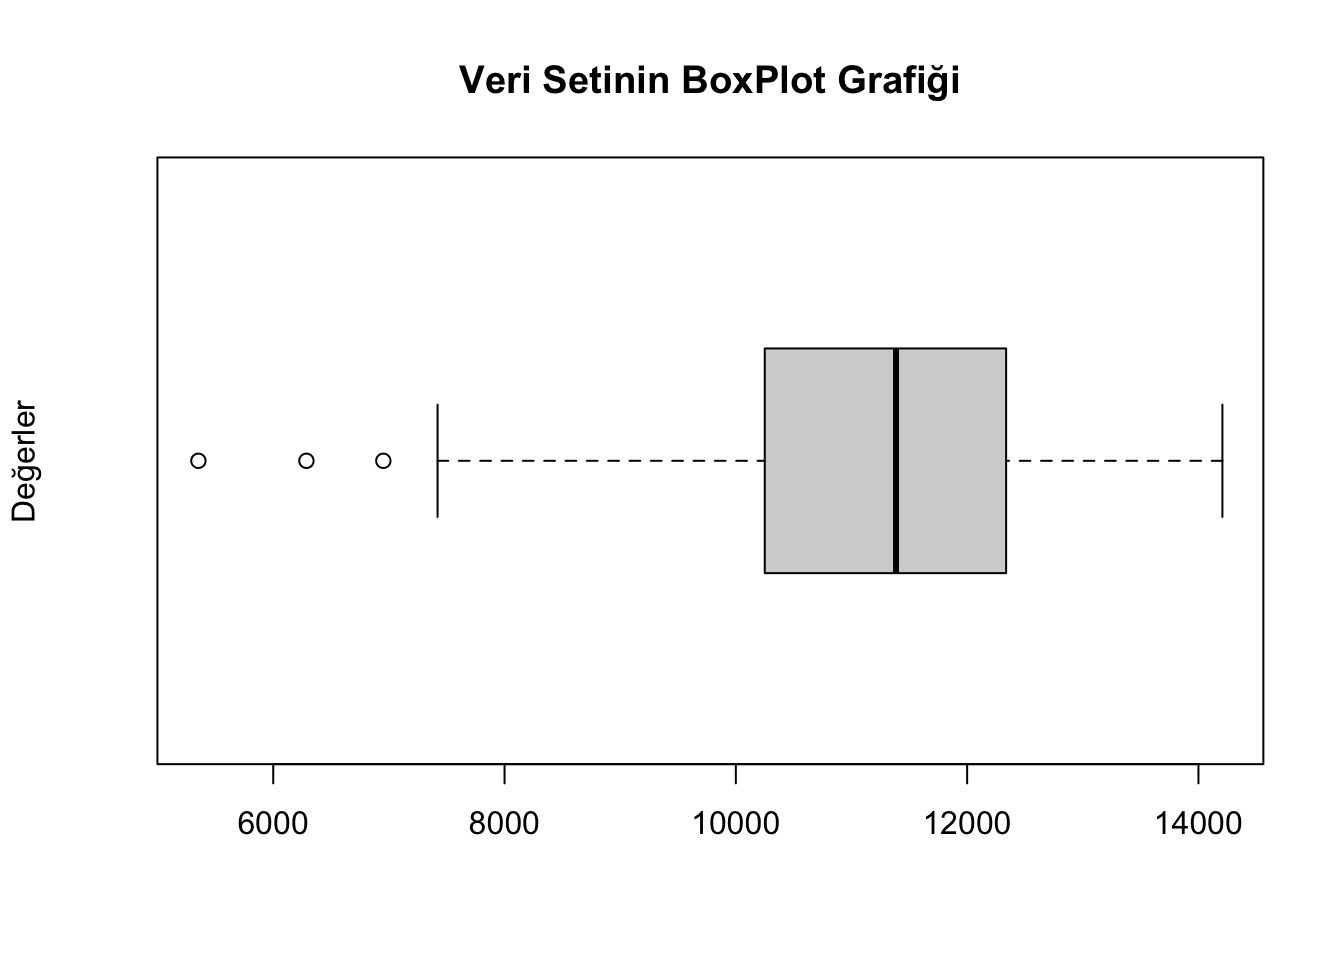{width="672"}

Aylık satış miktarlarının 11000-13000 bandında yığıldığı ve verinin
dağılımının sola çarpık olduğu gözükmektedir.

In [ ]:
%%R
ts.plot(ts_df,main="Verinin Time Series Plotu")

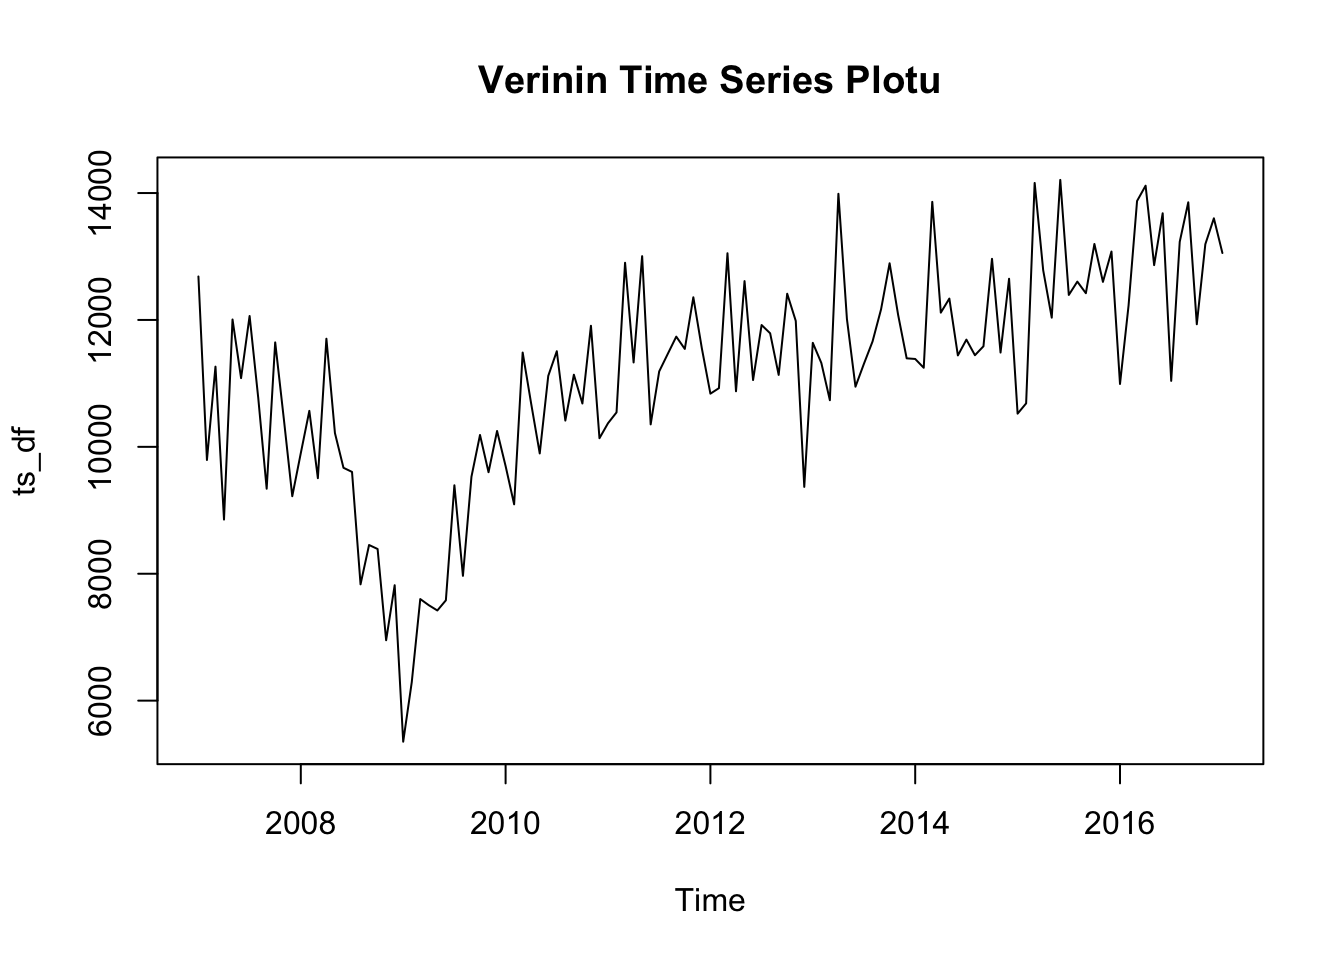{width="672"}

In [ ]:
%%R
plot(decompose(ts_df))

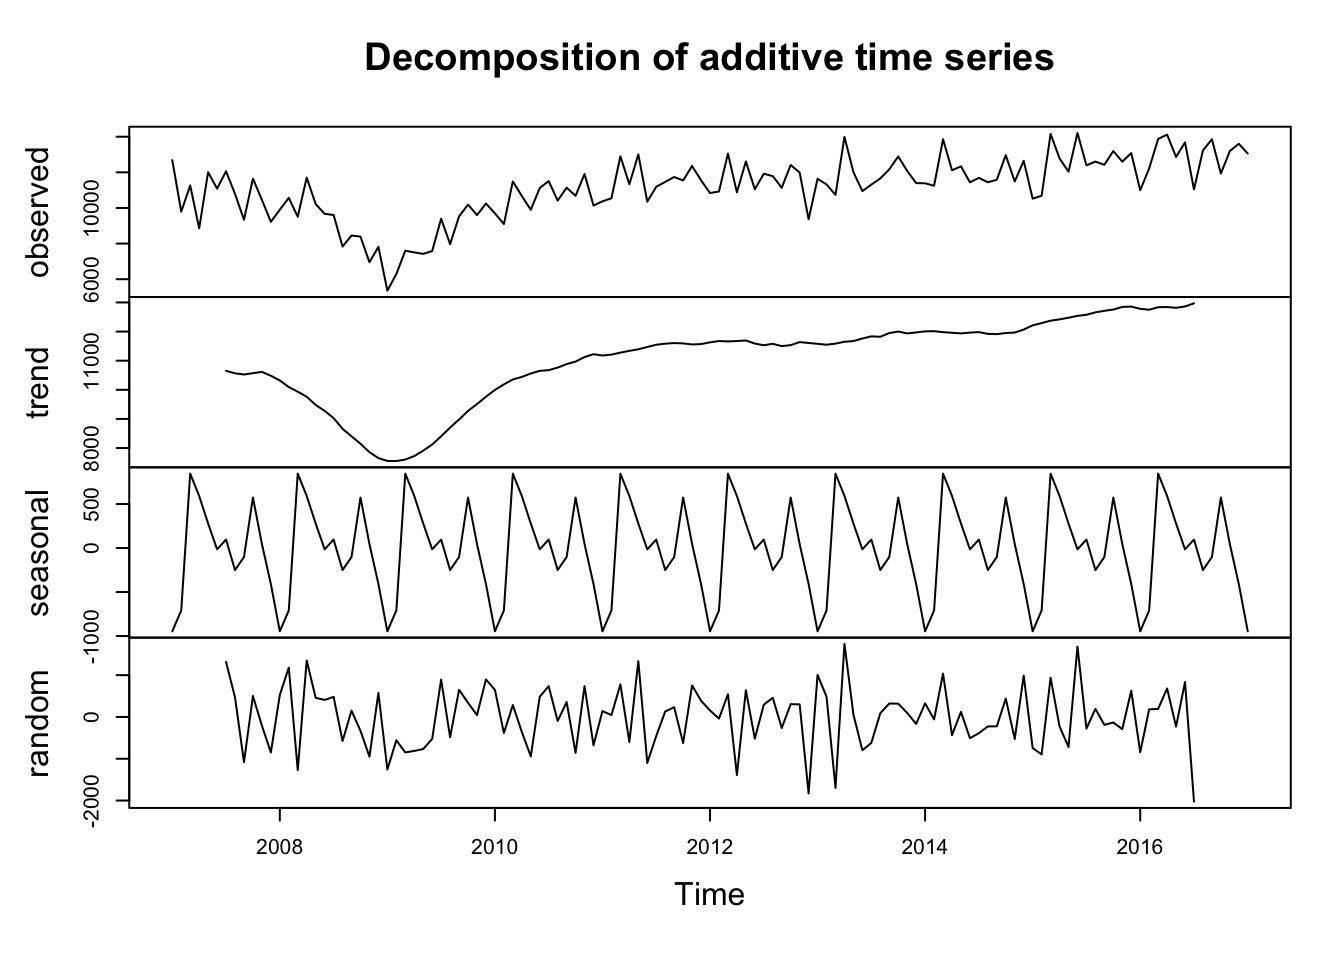{width="672"}

2009 yılında negatif yönlü bir trend oluştuğu ancak genel grafiğe
bakıldığında yukarı yönlü toplamsal bir trend olduğu gözükmektedir.
Ayrıca mevsimsel etki de belirgin bir şekilde gözükmektedir.
:::
::::

::: {#section-üssel-düzeltme-exponential-smoothing .section .level1}
# Üssel düzeltme (Exponential smoothing)

In [ ]:
%%R
holtwintermodel=HoltWinters(ts_df,seasonal="additive")
plot(holtwintermodel)

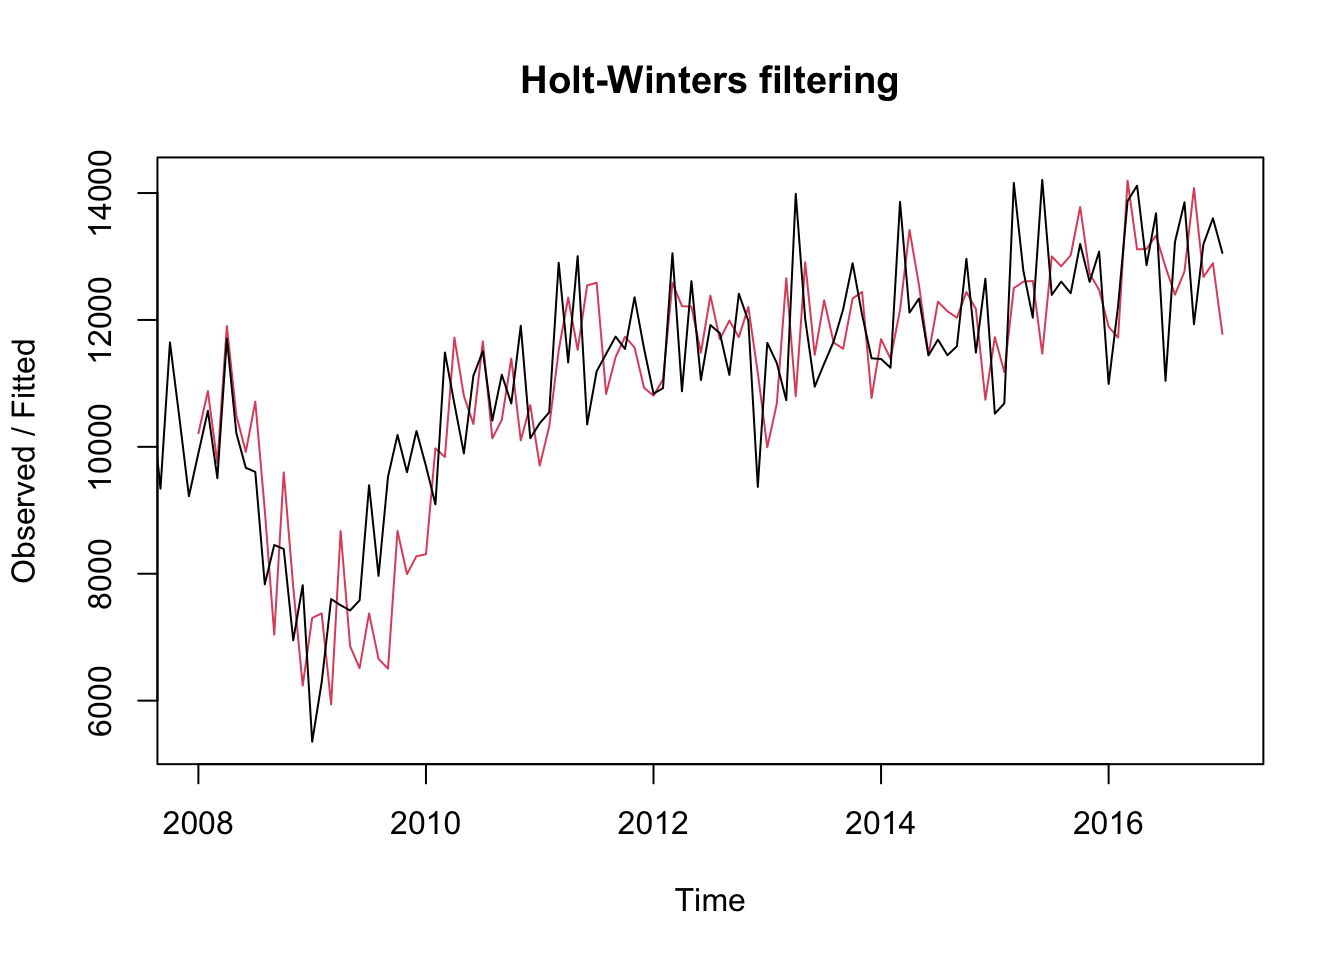{width="672"}

Mevsimselliğin toplamsal olduğu model seçilmiştir. Modelin veriyi iyi
şekilde taklit ettiği gözlemlenmiştir.

In [ ]:
%%R
holtwinterforecast=forecast(holtwintermodel,h=12)
plot(holtwinterforecast)

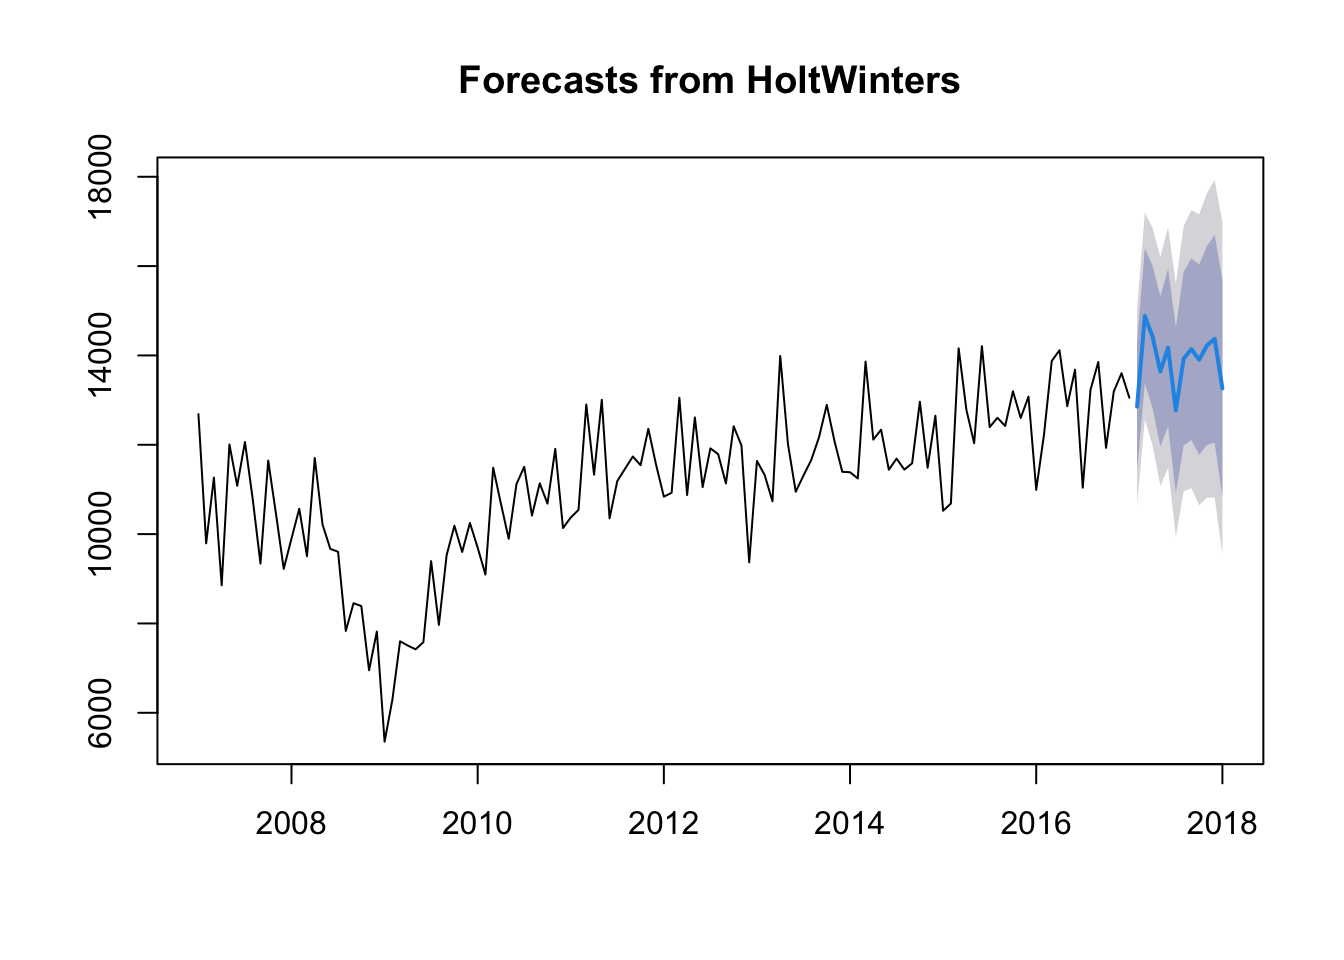{width="672"}

Modelin, %80 ve %95 güven aralığında dar aralıklarda tahminlerde
bulunduğu gözükmektedir. Tahminlemede mevsimsel etkinin devam ettiği
gözükmektedir. Sonuç olarak, iyi bir model elde edildiği söylenebilir.

12 aylık süreçte HoltWinters ile yapılan forecastler:

In [ ]:
%%R
holtwinterforecast

In [ ]:
##          Point Forecast    Lo 80    Hi 80     Lo 95    Hi 95
## Feb 2017       12855.28 11422.58 14287.97 10664.157 15046.39
## Mar 2017       14880.65 13369.42 16391.87 12569.419 17191.87
## Apr 2017       14417.20 12824.78 16009.63 11981.802 16852.60
## May 2017       13641.67 11965.52 15317.83 11078.214 16205.13
## Jun 2017       14173.20 12410.88 15935.53 11477.966 16868.44
## Jul 2017       12771.86 10921.04 14622.68  9941.272 15602.45
## Aug 2017       13924.86 11983.30 15866.43 10955.494 16894.23
## Sep 2017       14140.69 12106.21 16175.16 11029.224 17252.15
## Oct 2017       13903.83 11774.35 16033.31 10647.075 17160.59
## Nov 2017       14220.78 11994.28 16447.29 10815.636 17625.93
## Dec 2017       14372.87 12047.37 16698.37 10816.329 17929.41
## Jan 2018       13261.28 10834.88 15687.68  9550.426 16972.14

Tahminlerin 14000 bandında olduğu gözükmüştür.
:::

:::::::: {#section-sarima-modelin-seçilmesi .section .level1}
# SARIMA Modelin Seçilmesi

::: {#section-fark-alınmamış-veri .section .level2}
## Fark Alınmamış Veri

Fark Alınmamış Verinin ACF ve PACF Değerleri

In [ ]:
%%R
ggAcf(ts_df, lag.max = 50) + ggtitle("Orijinal Verinin ACF Değerleri")

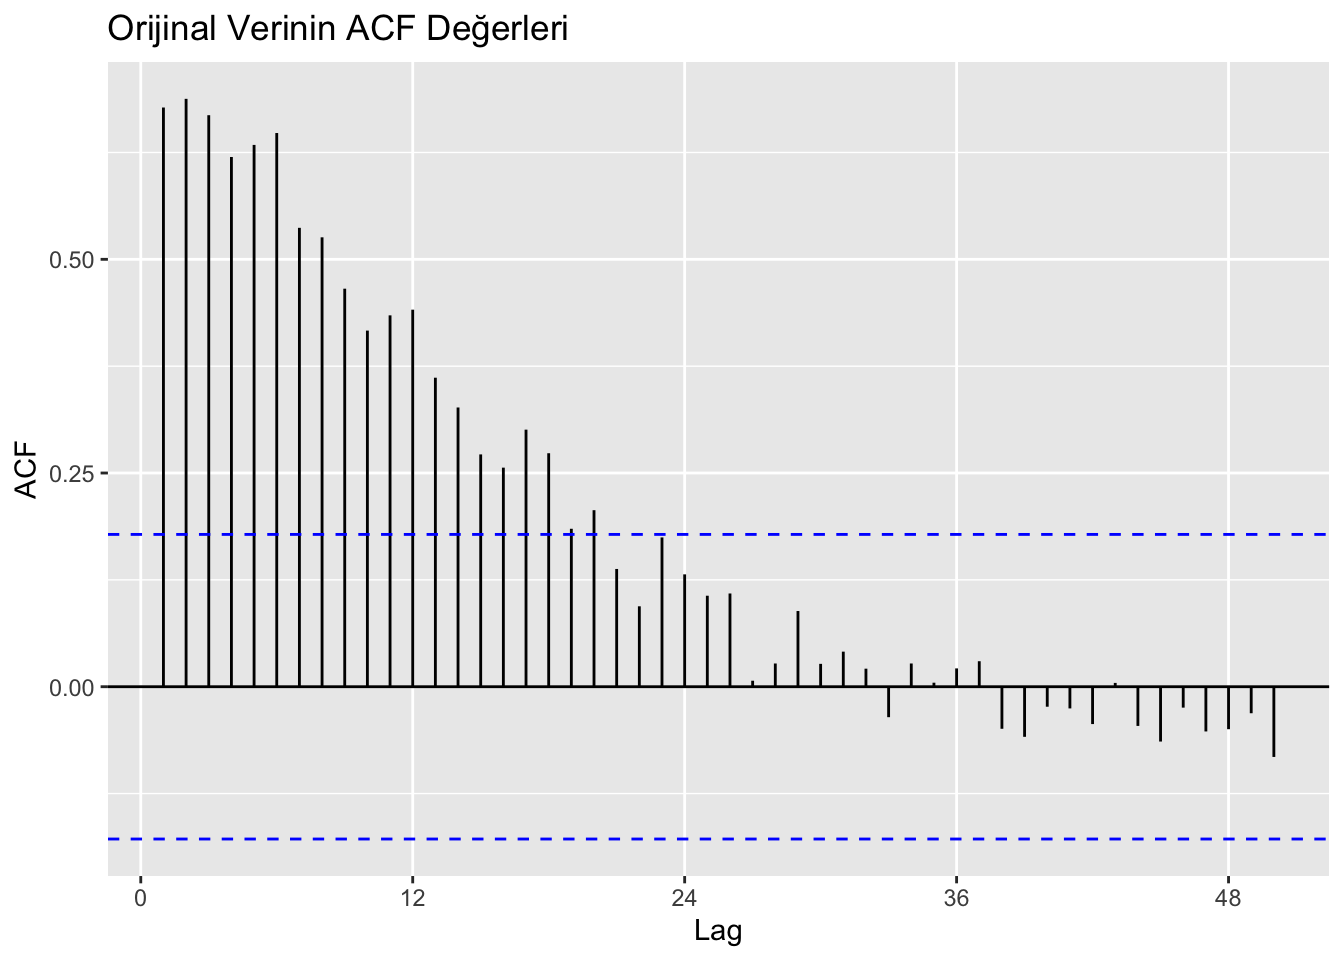{width="672"}

In [ ]:
%%R
ggPacf(ts_df, lag.max = 50) + ggtitle("Orijinal Verinin PACF Değerleri")

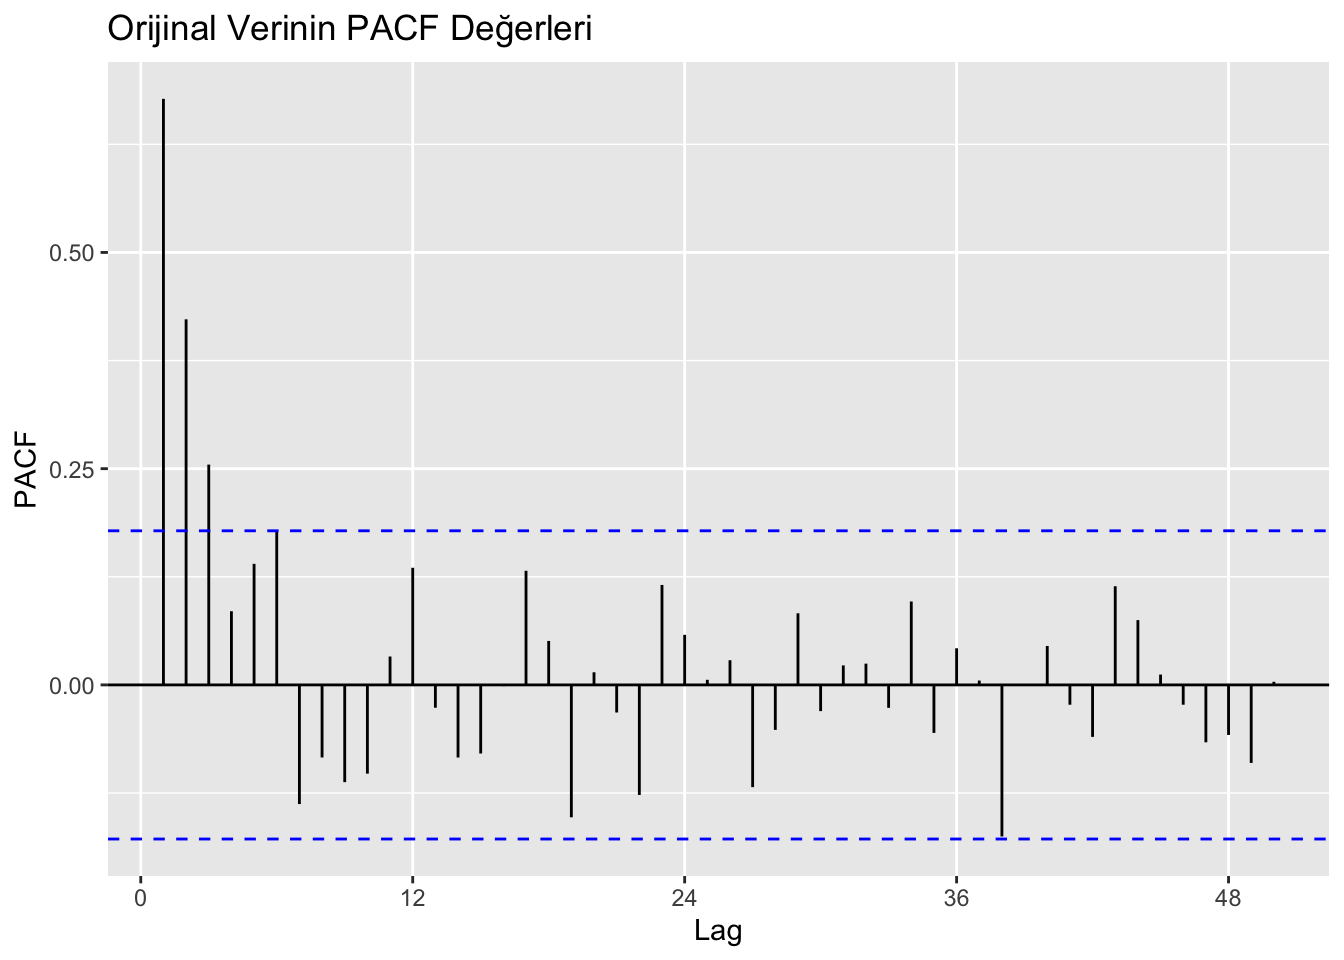{width="672"}

ACF'ye bakıldığında çok sayıda anlamlı lag olduğu ve verinin durağan
olmadığına karar verilmiştir. Bu yüzden 1 normal fark alınmış veriye
bakılmaya karar verilmiştir.
:::

::: {#section-normal-fark-alınmış-veri .section .level2}
## 1 Normal Fark Alınmış Veri

In [ ]:
%%R
diff1=diff(ts_df,1)
ggAcf(diff1, lag.max = 50) + ggtitle("1 Normal Fark Alınmış Verinin ACF Değerleri")

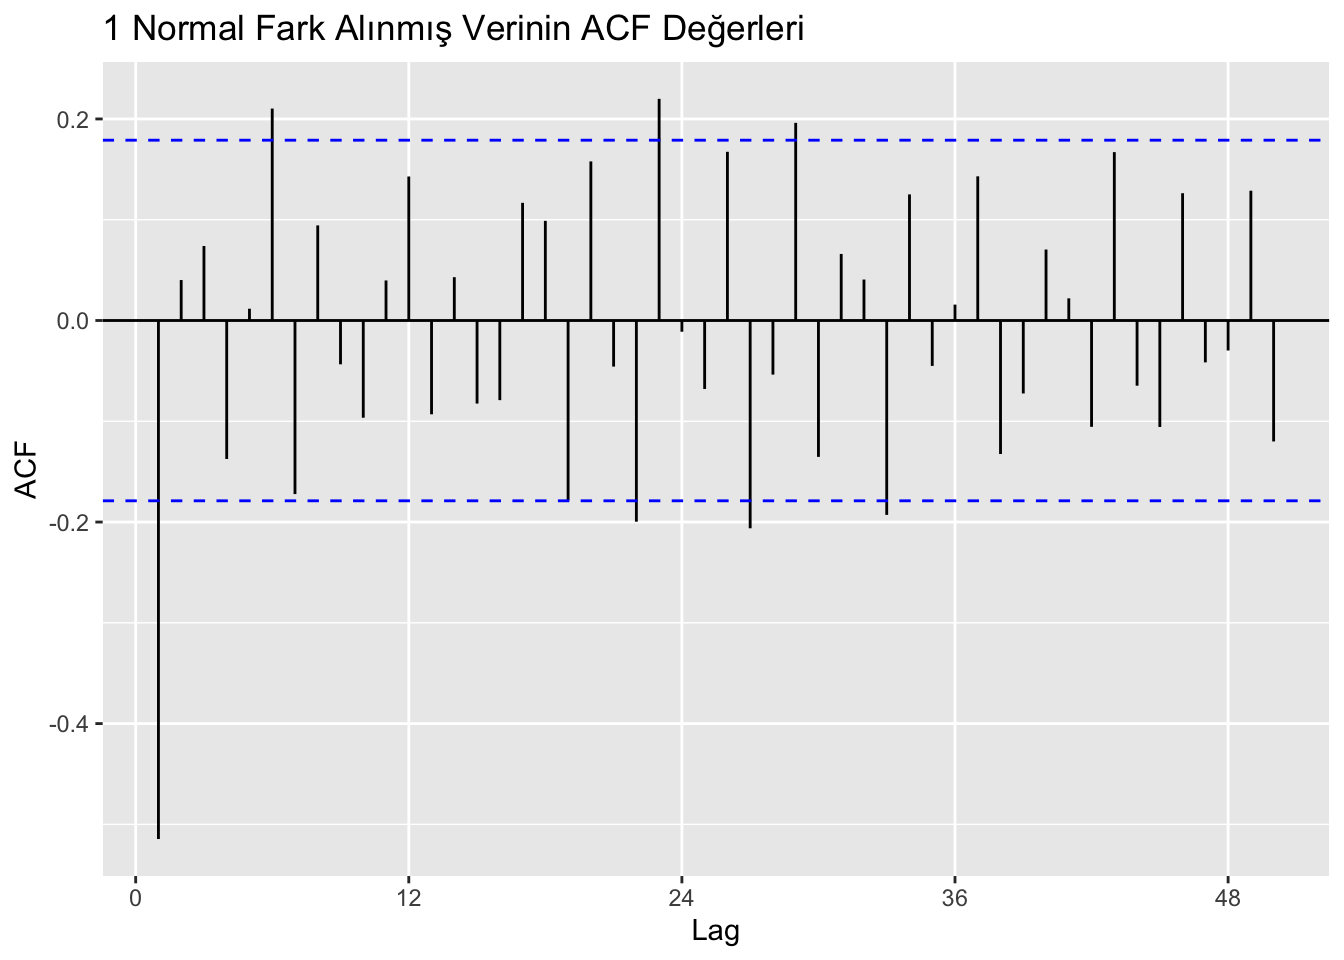{width="672"}

In [ ]:
%%R
ggPacf(diff1, lag.max = 50) + ggtitle("1 Normal Fark Alınmış Verinin PACF Değerleri")

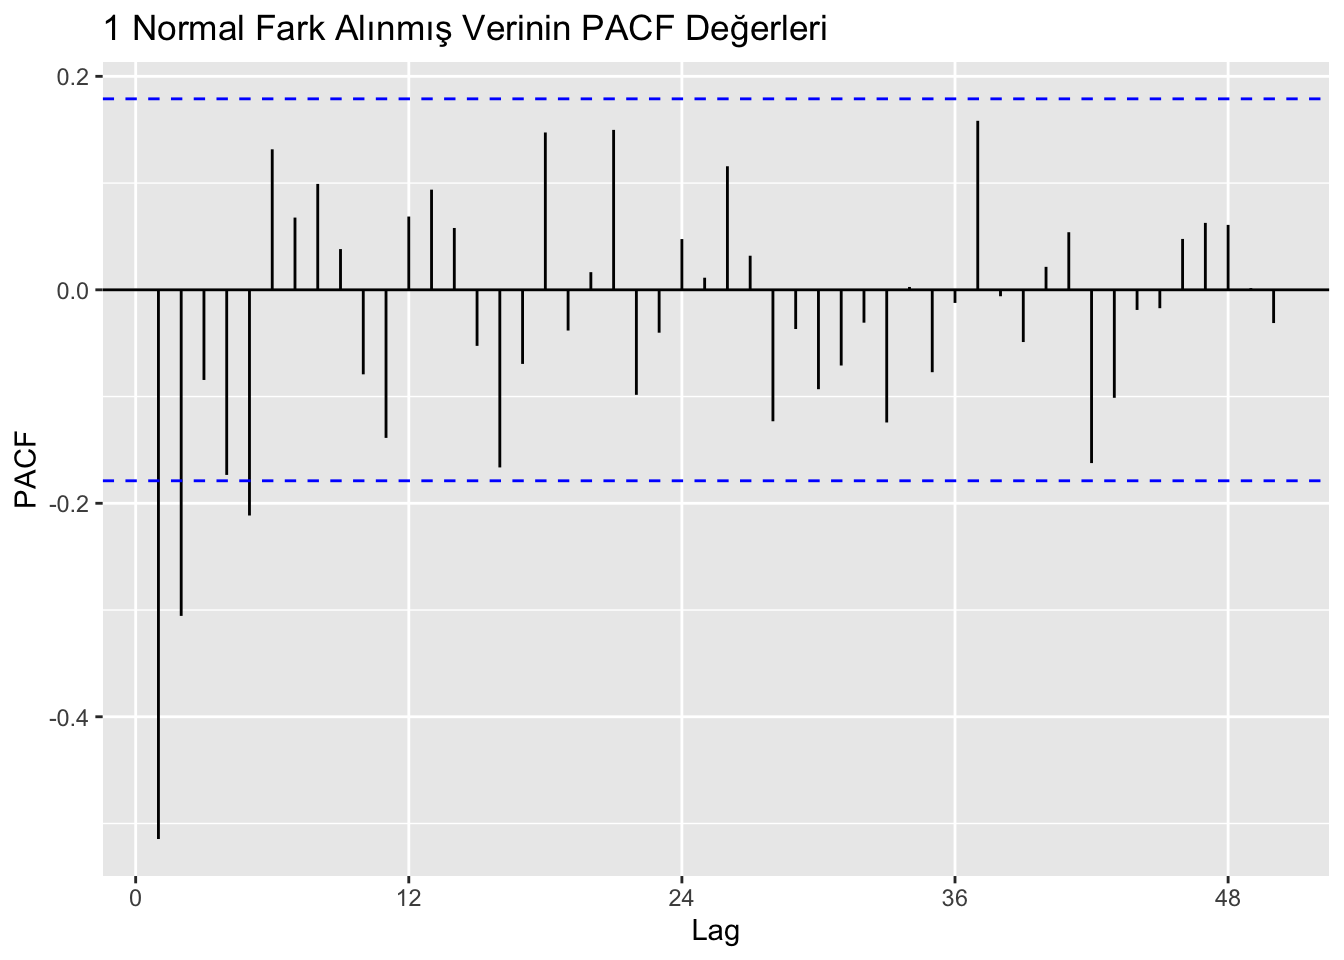{width="672"}

1 Normal fark alınmış verinin nispeten durağınlaştığı gözlemlenmiştir.
ACF'ye bakıldığında 1 mevsimsel olmayan anlamlı lag olduğu, PACF'ye
bakıldığında ise 2 olmayan anlamlı lag olduğu gözlemlenmiştir. Yani
mevsimsel olmayan kısım için ARIMA(2,1,0), ARIMA(0,1,1) ve ARIMA(2,1,1)
denenebilir. Mevsimsel kısım için ACF'de ve PACF'de mevsimsel kısımda
hiç anlamlı lag gözükmemektedir. Bu yüzden, her ikisinin de yavaşça
azaldığı varsayımında bulunulursa mevsimsel kısım için sadece
ARIMA(1,0,1) denenebilir. Ancak, yine de bir mevsimsel fark alınmasının
sağlıklı olduğuna karar verilmiştir.

In [ ]:
%%R
automodel=auto.arima(ts_df,stepwise=FALSE)
automodel

In [ ]:
## Series: ts_df 
## ARIMA(2,1,0)(1,0,1)[12] 
## 
## Coefficients:
##           ar1      ar2    sar1     sma1
##       -0.8077  -0.3906  0.8647  -0.6524
## s.e.   0.0881   0.0864  0.1092   0.1712
## 
## sigma^2 = 1117390:  log likelihood = -1005.82
## AIC=2021.65   AICc=2022.18   BIC=2035.59

Auto Arima'nın önerdiği model bir önceki paragrafta bahsedilen görüşü
desteklemektedir. Ancak, 1 mevsimsel fark alınmış veriye de
bakılmalıdır.

In [ ]:
%%R
coeftest(automodel)

In [ ]:
## 
## z test of coefficients:
## 
##       Estimate Std. Error z value  Pr(>|z|)    
## ar1  -0.807714   0.088145 -9.1635 < 2.2e-16 ***
## ar2  -0.390557   0.086379 -4.5214 6.142e-06 ***
## sar1  0.864741   0.109189  7.9196 2.382e-15 ***
## sma1 -0.652411   0.171233 -3.8101 0.0001389 ***
## ---
## Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

ARIMA(2,1,0)(1,0,1) için ar1, ar2, sar1, sma1'in hepsinin anlamlı olduğu
gözükmüştür.

In [ ]:
%%R
tsdiag(automodel)

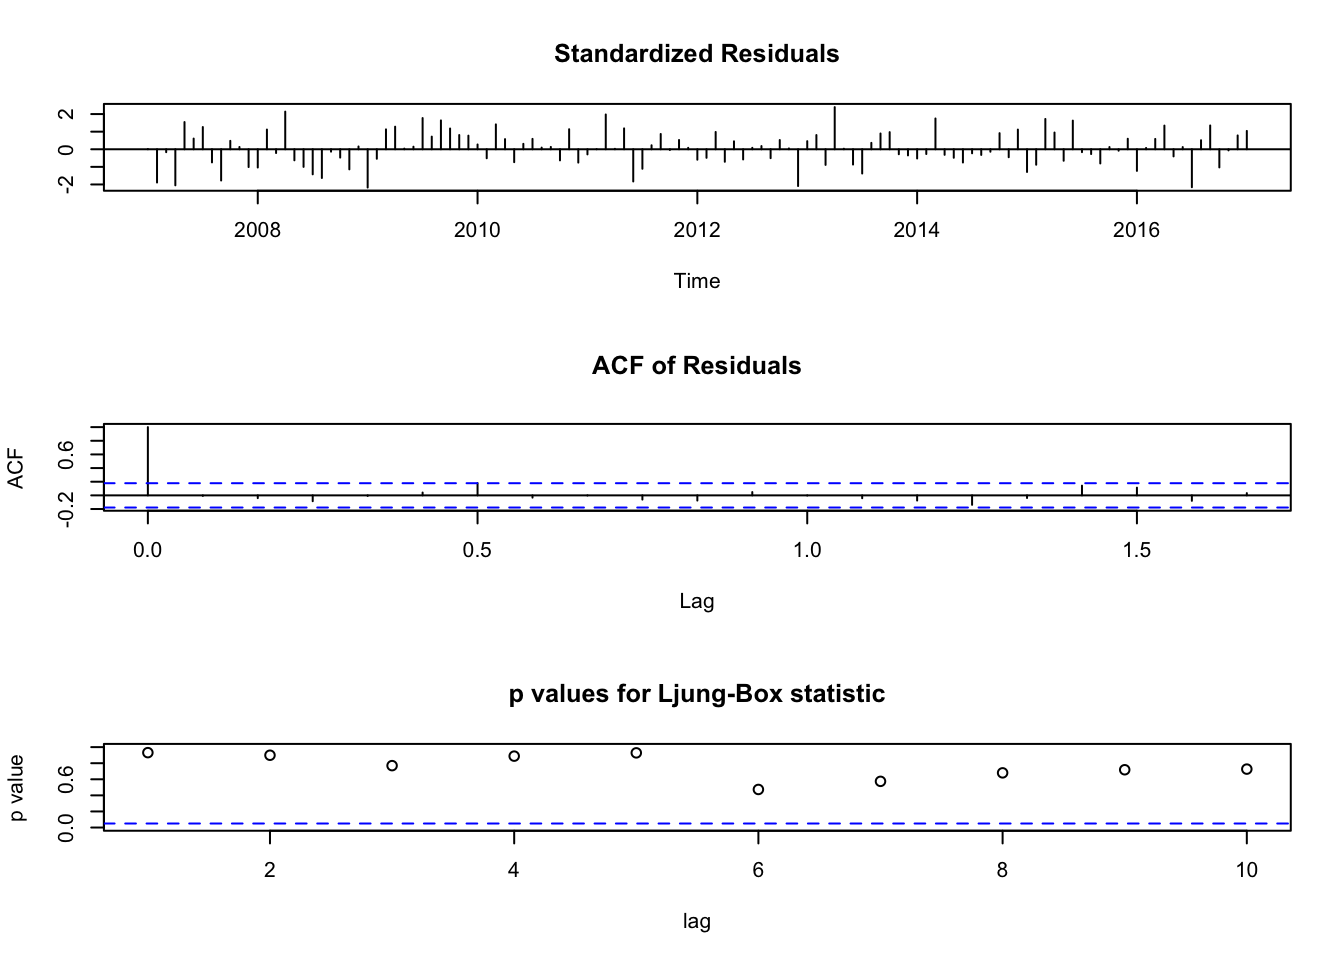{width="672"}

Standardize edilmiş artıklara bakıldığında 0 etrafında bir dağılıma
sahip olduğu gözlemlenmiştir. Artıklar arasında bir tane anlamlı
otokorelasyon gözükmektedir ancak sınırdan ve bir tane olduğu için
görmezden gelinebilir. p value'lar da sınırın oldukça üstünde olduğu
gözükmektedir.

In [ ]:
%%R
checkresiduals(automodel)

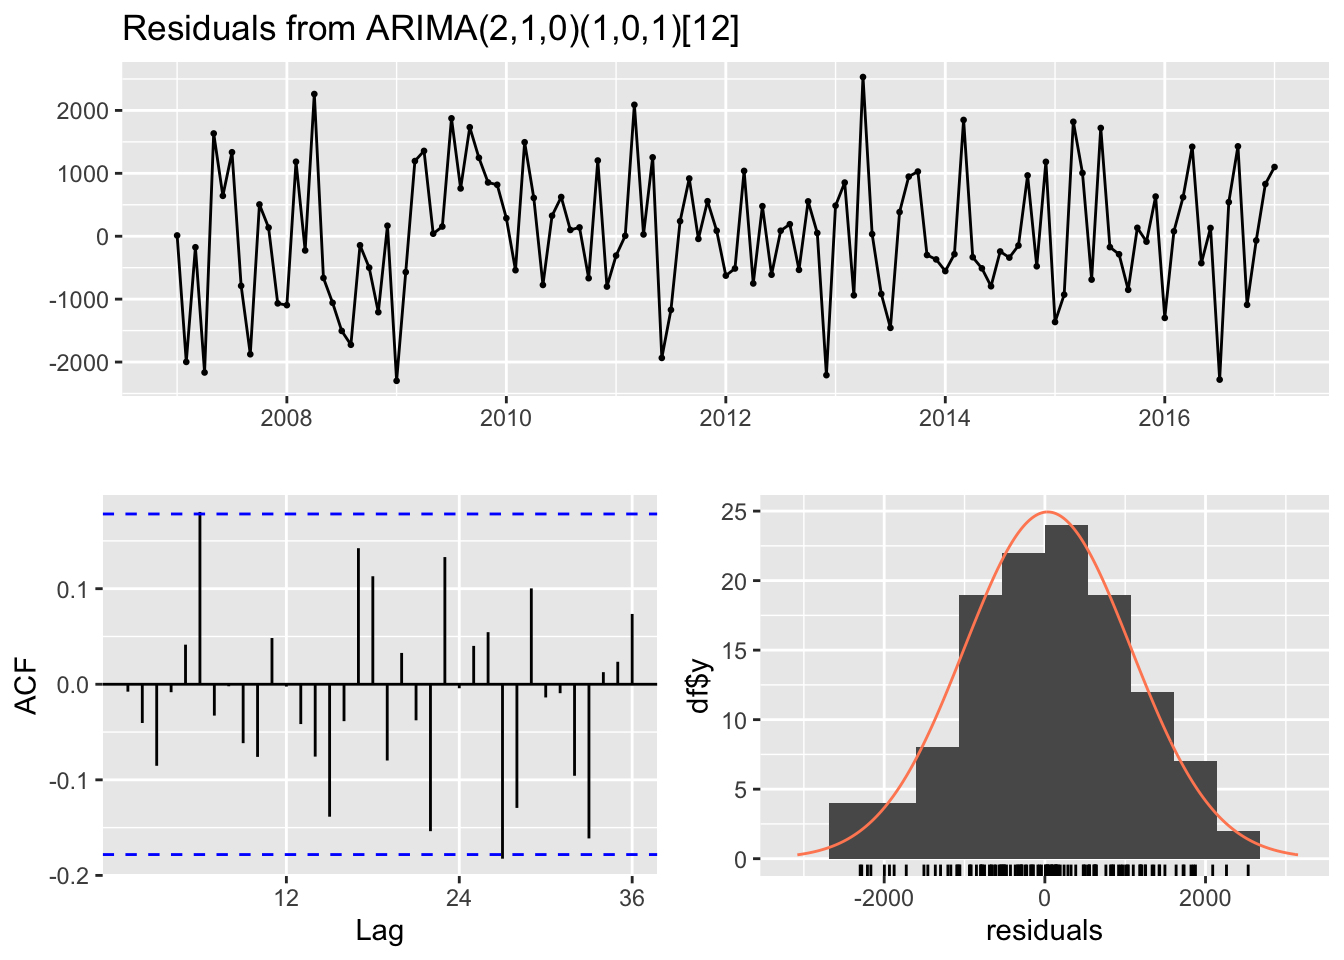{width="672"}

In [ ]:
## 
##  Ljung-Box test
## 
## data:  Residuals from ARIMA(2,1,0)(1,0,1)[12]
## Q* = 23.536, df = 20, p-value = 0.2633
## 
## Model df: 4.   Total lags used: 24

Bir önceki paragraftaki anlatılanları bu grafik desteklemektedir. Ek
olarak artık dağılımların normal dağılıma uygun olduğuna sezgisel olarak
karar verilmiştir.

In [ ]:
%%R
shapiro.test(automodel$residuals)

In [ ]:
## 
##  Shapiro-Wilk normality test
## 
## data:  automodel$residuals
## W = 0.99186, p-value = 0.7026

Shapiro-Wilk normality testi sonucunda, H0 hipotezi reddedilemez, yani
veri setinin artık değerleri normal dağılıma sahip olduğu kabul
edilebilir.

In [ ]:
%%R
Box.test(automodel$residuals,lag=6)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  automodel$residuals
## X-squared = 5.2357, df = 6, p-value = 0.514

In [ ]:
%%R
Box.test(automodel$residuals,lag=12)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  automodel$residuals
## X-squared = 6.8082, df = 12, p-value = 0.87

In [ ]:
%%R
Box.test(automodel$residuals,lag=24)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  automodel$residuals
## X-squared = 20.289, df = 24, p-value = 0.6802

In [ ]:
%%R
Box.test(automodel$residuals,lag=36)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  automodel$residuals
## X-squared = 33.149, df = 36, p-value = 0.6049

p valueları, 6.lagten 12.lage geçerken artış, 24 ve 36. laglerde ise
düşüş gözlemlenmiştir. Ancak p valueları genel olarak yeterince yüksek
denebilir. Bu doğrultuda model geçerlidir denebilir. Ancak, daha iyi
modeller mümkün olup olmadığı için 1 mevsimsel fark alınmış verinin de
kontrol edilmesi gereklidir.
:::

::: {#section-normal-fark-ve-1-mevsimsel-fark-alınmış-veri .section .level2}
## 1 Normal Fark ve 1 Mevsimsel Fark Alınmış Veri

In [ ]:
%%R
diff112=diff(diff1,12)
ggAcf(diff112, lag.max = 50) + ggtitle("1 Normal Fark ve 1 Mevsimsel Fark Alınmış Verinin ACF Değerleri")

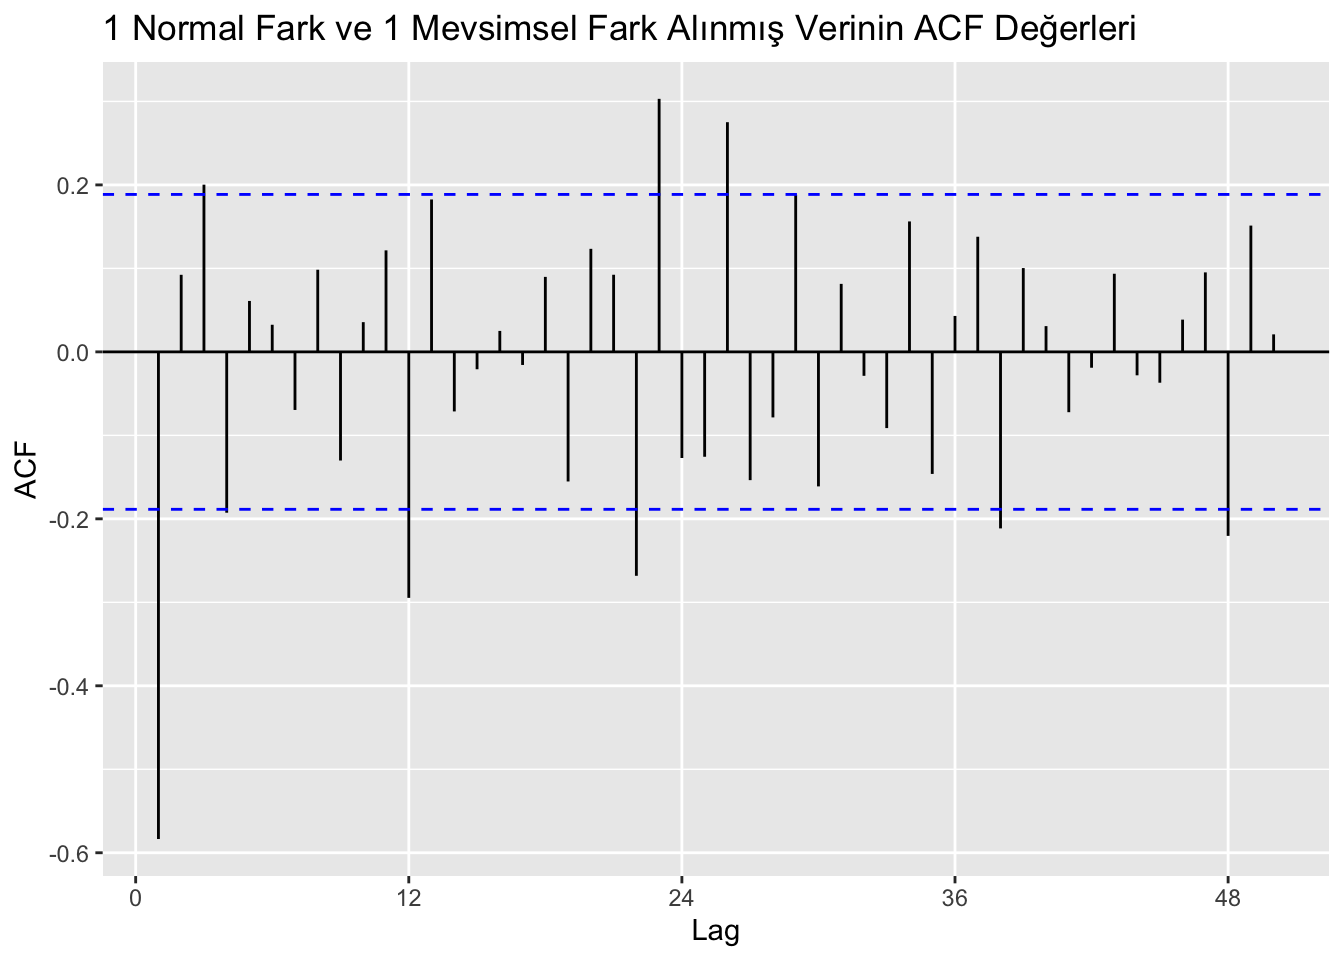{width="672"}

In [ ]:
%%R
ggPacf(diff112, lag.max = 50) + ggtitle("1 Normal Fark 1 Mevsimsel Fark Alınmış Verinin PACF Değerleri")

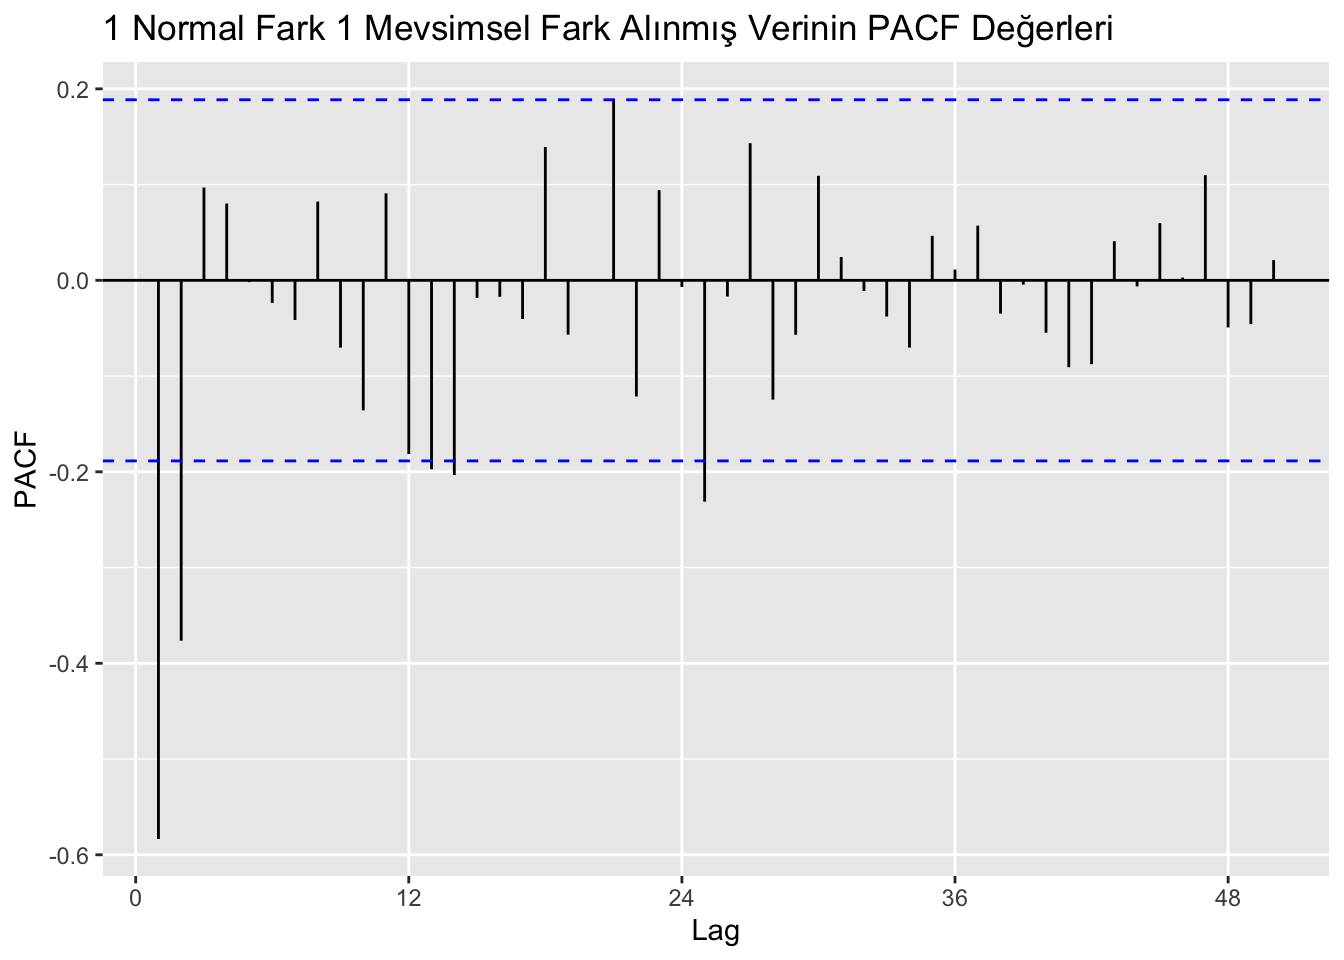{width="672"}

ACF'ye bakıldığında mevsimsel kısımda 12, 24, 36 , 48'de yavaşça azalan
anlamlı lagler gözükmüştür. PACF'de ise 12 ve 24. laglerde spikeların
olduğu ve 36. ve 48.laglerde cut off olduğu gözükmüştür. Bu yüzden
mevsimsel kısım için ARIMA (2,1,0) olduğuna karar verilmiştir.

In [ ]:
%%R
model1=arima(ts_df,order=c(2,1,0),seasonal=list(order=c(2,1,0),period=12))
model1

In [ ]:
## 
## Call:
## arima(x = ts_df, order = c(2, 1, 0), seasonal = list(order = c(2, 1, 0), period = 12))
## 
## Coefficients:
##           ar1      ar2     sar1     sar2
##       -0.8886  -0.4564  -0.6255  -0.3702
## s.e.   0.0882   0.0886   0.1071   0.1098
## 
## sigma^2 estimated as 1199163:  log likelihood = -912.74,  aic = 1835.47

In [ ]:
%%R
coeftest(model1)

In [ ]:
## 
## z test of coefficients:
## 
##       Estimate Std. Error  z value  Pr(>|z|)    
## ar1  -0.888600   0.088228 -10.0716 < 2.2e-16 ***
## ar2  -0.456390   0.088562  -5.1533 2.559e-07 ***
## sar1 -0.625544   0.107068  -5.8425 5.142e-09 ***
## sar2 -0.370170   0.109778  -3.3720 0.0007462 ***
## ---
## Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Bütün parametrelerin anlamlı olduğu gözlenmiştir.

In [ ]:
%%R
model2=arima(ts_df,order=c(0,1,1),seasonal=list(order=c(2,1,0),period=12))
model2

In [ ]:
## 
## Call:
## arima(x = ts_df, order = c(0, 1, 1), seasonal = list(order = c(2, 1, 0), period = 12))
## 
## Coefficients:
##           ma1     sar1     sar2
##       -0.6508  -0.5708  -0.3555
## s.e.   0.0591   0.1026   0.1068
## 
## sigma^2 estimated as 1422079:  log likelihood = -921.37,  aic = 1850.74

In [ ]:
%%R
coeftest(model2)

In [ ]:
## 
## z test of coefficients:
## 
##       Estimate Std. Error  z value  Pr(>|z|)    
## ma1  -0.650765   0.059119 -11.0077 < 2.2e-16 ***
## sar1 -0.570844   0.102588  -5.5644  2.63e-08 ***
## sar2 -0.355509   0.106763  -3.3299 0.0008688 ***
## ---
## Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Bütün parametrelerin anlamlı olduğu gözlenmiştir.

In [ ]:
%%R
model3=arima(ts_df,order=c(2,1,1),seasonal=list(order=c(2,1,0),period=12))
model3

In [ ]:
## 
## Call:
## arima(x = ts_df, order = c(2, 1, 1), seasonal = list(order = c(2, 1, 0), period = 12))
## 
## Coefficients:
##           ar1      ar2      ma1     sar1     sar2
##       -0.8466  -0.4313  -0.0565  -0.6295  -0.3711
## s.e.   0.1674   0.1257   0.1864   0.1076   0.1100
## 
## sigma^2 estimated as 1197526:  log likelihood = -912.69,  aic = 1837.38

In [ ]:
%%R
coeftest(model3)

In [ ]:
## 
## z test of coefficients:
## 
##       Estimate Std. Error z value  Pr(>|z|)    
## ar1  -0.846647   0.167374 -5.0584 4.227e-07 ***
## ar2  -0.431329   0.125703 -3.4313 0.0006006 ***
## ma1  -0.056534   0.186417 -0.3033 0.7616863    
## sar1 -0.629532   0.107614 -5.8499 4.918e-09 ***
## sar2 -0.371083   0.110040 -3.3723 0.0007455 ***
## ---
## Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

ma1'in anlamlı olmadığı gözüktüğü için bu modelden vazgeçilmiştir.

In [ ]:
%%R
tsdiag(model1)

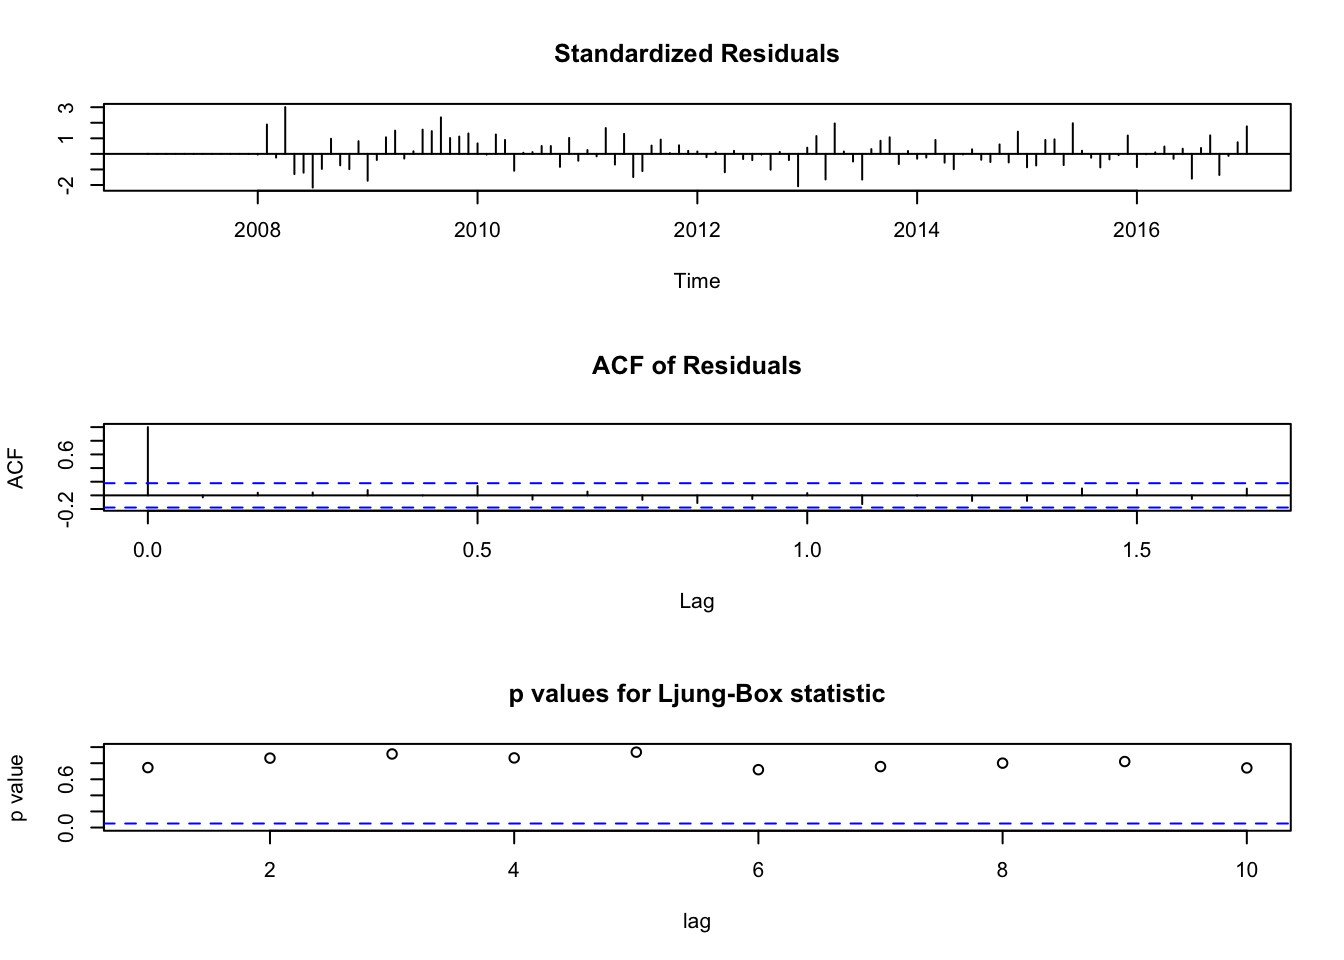{width="672"}

Standardize edilmiş artıklara bakıldığında 0 etrafında bir dağılıma
sahip olduğu gözlemlenmiştir. Artıklar arasında bir otokorelasyon
gözükmemektedir. p value'lar da sınırın oldukça üstünde olduğu
gözükmektedir.

In [ ]:
%%R
tsdiag(model2)

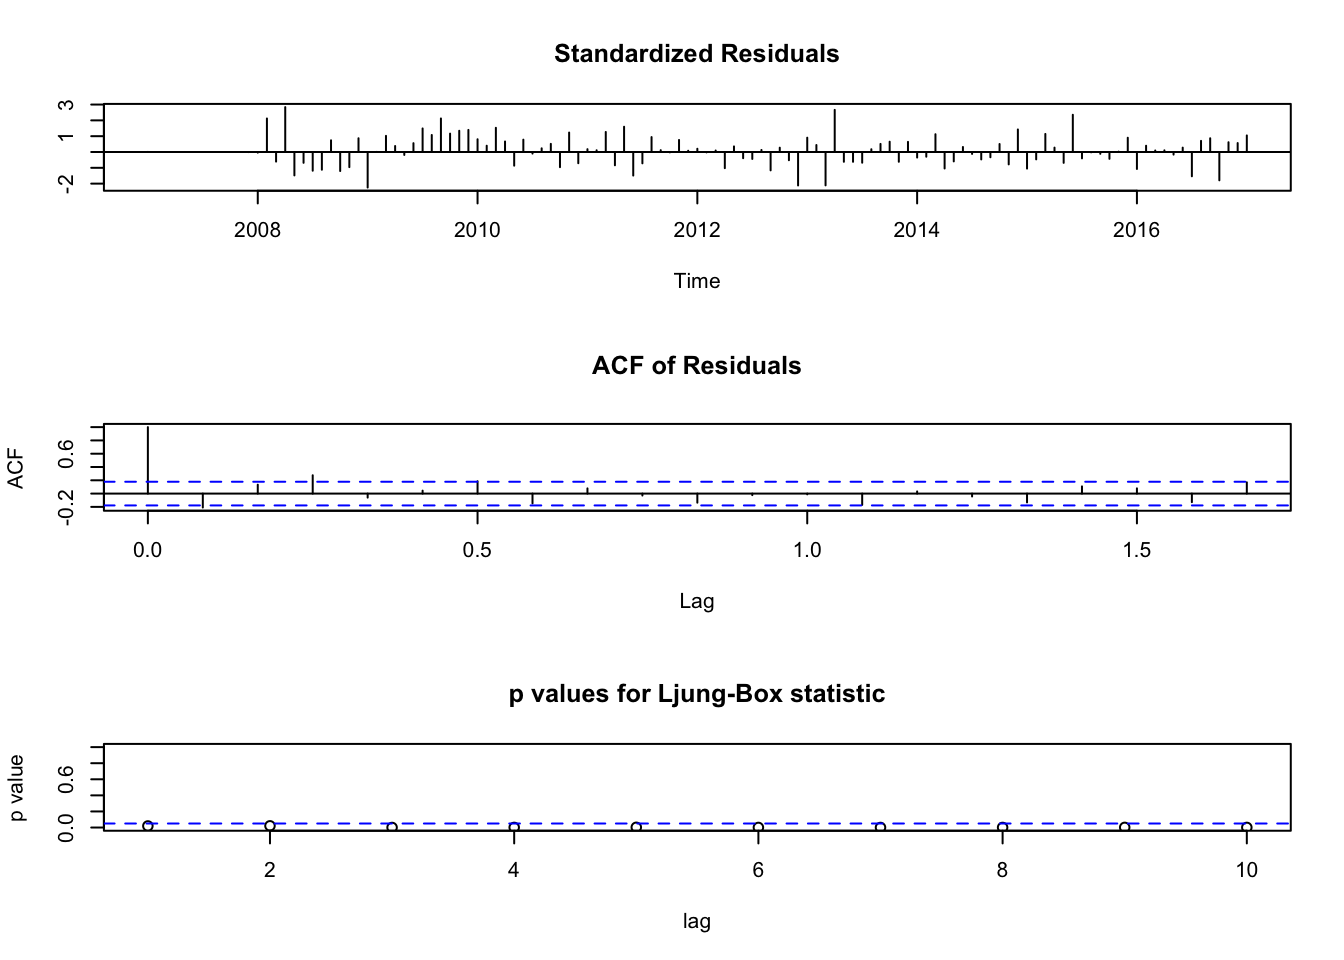{width="672"}

Standaridize edilmiş artıklara bakıldığında 0 etrafında varyans olduğu
gözükmektedir Artıklar arasında yer yer anlamlı otokorelasyon
gözükmektedir. p value'lar ise eşik değerin altında değerler aldığı
gözlemlenmiştir.

In [ ]:
%%R
Box.test(model1$residuals,lag=6)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model1$residuals
## X-squared = 3.4712, df = 6, p-value = 0.7478

In [ ]:
%%R
Box.test(model1$residuals,lag=12)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model1$residuals
## X-squared = 6.8043, df = 12, p-value = 0.8703

In [ ]:
%%R
Box.test(model1$residuals,lag=24)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model1$residuals
## X-squared = 17.478, df = 24, p-value = 0.8276

In [ ]:
%%R
Box.test(model1$residuals,lag=36)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model1$residuals
## X-squared = 29.715, df = 36, p-value = 0.7608

p value'ların mevsimsel kısmının Ljung Box değerleri için yüksek olduğu
gözlenmiştir.

In [ ]:
%%R
Box.test(model2$residuals,lag=6)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model2$residuals
## X-squared = 21.572, df = 6, p-value = 0.001447

In [ ]:
%%R
Box.test(model2$residuals,lag=12)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model2$residuals
## X-squared = 27.375, df = 12, p-value = 0.006822

In [ ]:
%%R
Box.test(model2$residuals,lag=24)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model2$residuals
## X-squared = 51.939, df = 24, p-value = 0.0007967

In [ ]:
%%R
Box.test(model2$residuals,lag=36)

In [ ]:
## 
##  Box-Pierce test
## 
## data:  model2$residuals
## X-squared = 75.228, df = 36, p-value = 0.0001383

p value'ların mevsimsel kısmının Ljung Box değerleri için düşük olduğu
gözlenmiştir.

In [ ]:
%%R
checkresiduals(model1)

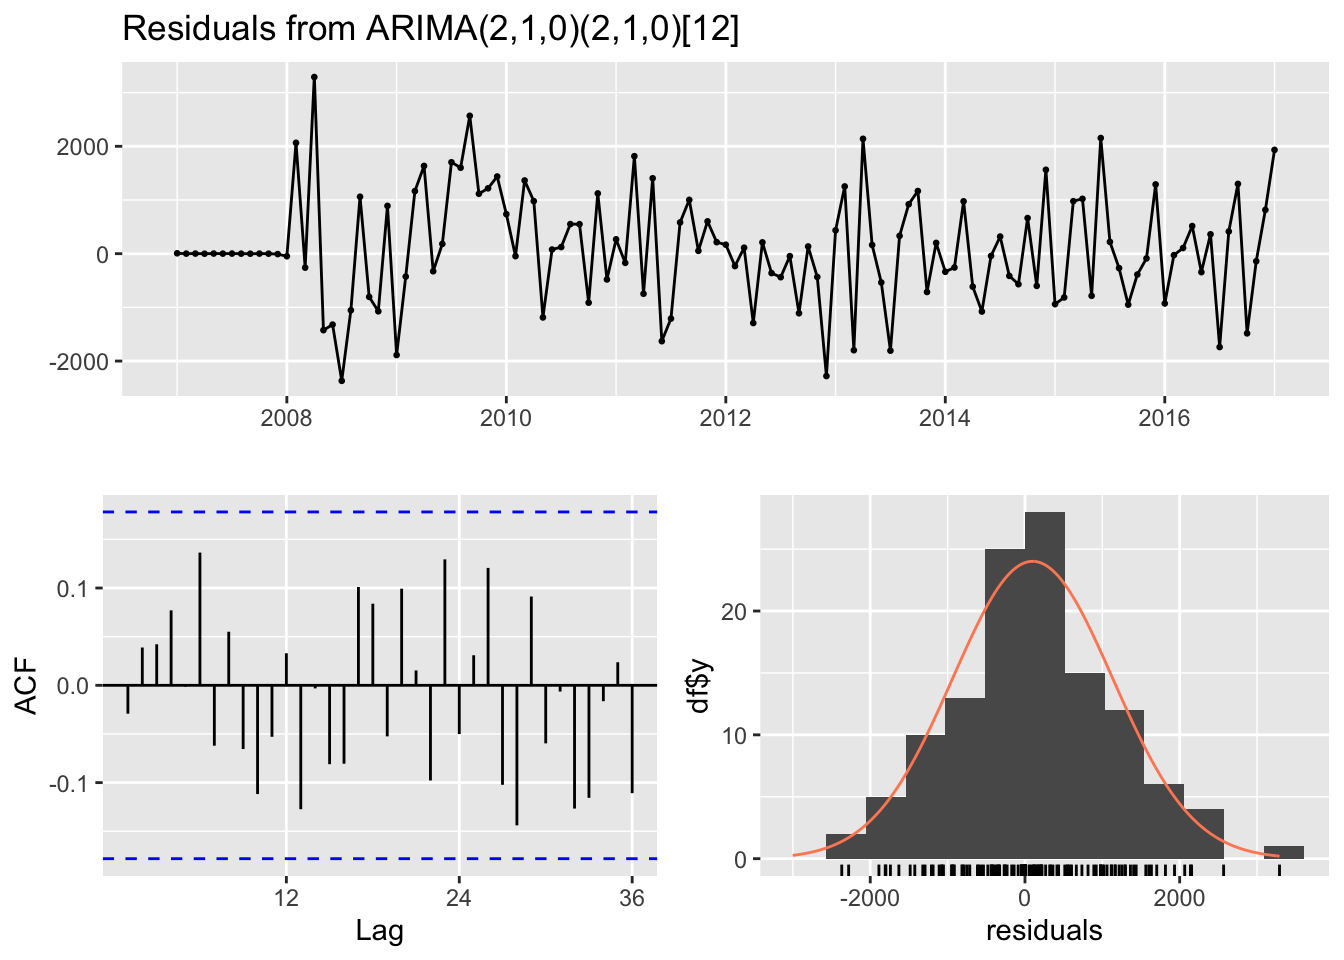{width="672"}

In [ ]:
## 
##  Ljung-Box test
## 
## data:  Residuals from ARIMA(2,1,0)(2,1,0)[12]
## Q* = 20.17, df = 20, p-value = 0.4474
## 
## Model df: 4.   Total lags used: 24

Artıklar arasında otokorelasyon olmadığı bu grafikte de
desteklenmektedir. Artıkların 0 etrafında dağılım gösterdiği
gözükmektedir. Artıkların normal dağılıma uyduğuna sezgisel olarak karar
verilmiştir.

In [ ]:
%%R
checkresiduals(model2)

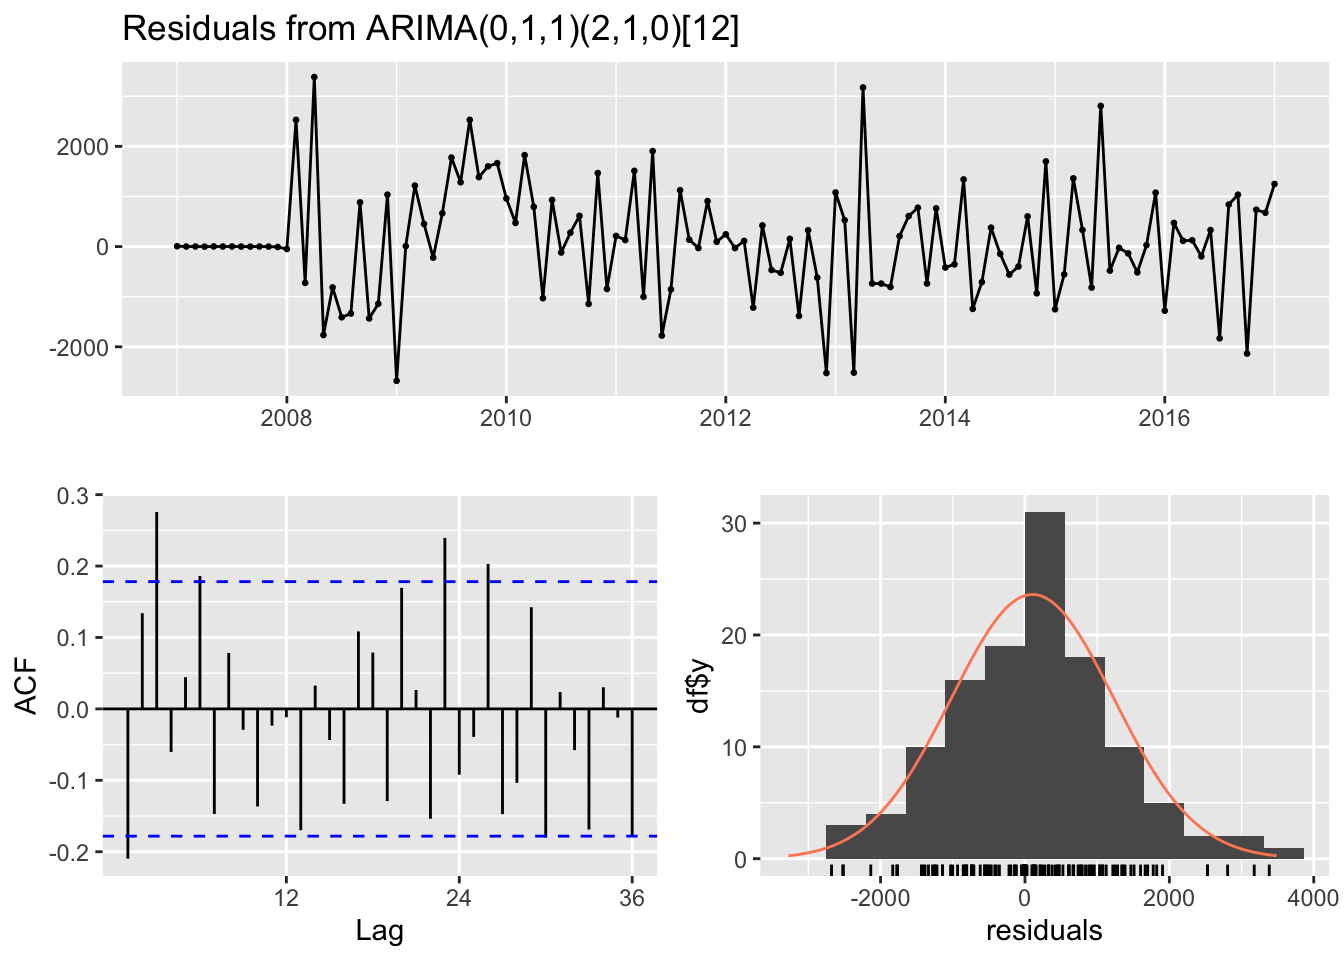{width="672"}

In [ ]:
## 
##  Ljung-Box test
## 
## data:  Residuals from ARIMA(0,1,1)(2,1,0)[12]
## Q* = 58.645, df = 21, p-value = 2.044e-05
## 
## Model df: 3.   Total lags used: 24

Artıklar arasındaki otokorelasyon gözükmektedir. Artıkların 0 etrafında
bir dağılım gösterdiği görülmüştür. Artıkların normal dağılıma uyduğuna
sezgisel olarak karar verilmiştir.

In [ ]:
%%R
shapiro.test(model1$residuals)

In [ ]:
## 
##  Shapiro-Wilk normality test
## 
## data:  model1$residuals
## W = 0.9899, p-value = 0.5193

Shapiro-Wilk normality testi sonucuna göre, model1'in residual değerleri
normal dağılıma sahip olmadığına dair yeterli kanıt bulunmamaktadır.

In [ ]:
%%R
shapiro.test(model2$residuals)

In [ ]:
## 
##  Shapiro-Wilk normality test
## 
## data:  model2$residuals
## W = 0.98661, p-value = 0.2797

Shapiro-Wilk normality testi sonucuna göre, model2'nin residual
değerleri normal dağılıma sahip olmadığına dair yeterli kanıt
bulunmamaktadır. Dolayısıyla model 2'nin de yeterli olmadığına karar
verilmiştir.
:::

::: {#section-sarima-modellerin-kıyaslanması .section .level2}
## SARIMA Modellerin Kıyaslanması

+-----+---------+-----------+---------+----------+-------+-------+
| Mo  | Bütün   | A         | A       | P        | Log   | AIC   |
| del | Para    | rtıklarda | rtıklar | V        | Likel | Değe  |
|     | metrele | Anlamlı   | Normal  | alue'lar | ihood | rleri |
|     | Sign    | Otok      | D       | Eşik     | Değe  |       |
|     | ificant | orelasyon | ağılıma | Değerin  | rleri |       |
|     | mı?     | var mı?   | Uygun   | Üstünde  |       |       |
|     |         |           | mu?     | mi?      |       |       |
+=====+=========+===========+=========+==========+=======+=======+
| AR  | EVET✅  | HAYIR✅   | EVET✅  | EVET✅   | -10   | 20    |
| IMA |         |           |         |          | 05.82 | 21.65 |
|     |         |           |         |          |       |       |
| (2  |         |           |         |          |       |       |
| ,1, |         |           |         |          |       |       |
| 0)( |         |           |         |          |       |       |
| 1,0 |         |           |         |          |       |       |
| ,1) |         |           |         |          |       |       |
+-----+---------+-----------+---------+----------+-------+-------+
| AR  | EVET✅  | HAYIR✅   | EVET✅  | EVET✅   | -9    | 18    |
| IMA |         |           |         |          | 12.74 | 35.47 |
|     |         |           |         |          |       |       |
| (2  |         |           |         |          |       |       |
| ,1, |         |           |         |          |       |       |
| 0)( |         |           |         |          |       |       |
| 2,1 |         |           |         |          |       |       |
| ,0) |         |           |         |          |       |       |
+-----+---------+-----------+---------+----------+-------+-------+
| AR  | EVET✅  | EVET❌    | EVET✅  | HAYIR❌  | DEĞ   | DEĞ   |
| IMA |         |           |         |          | ERLEN | ERLEN |
|     |         |           |         |          | DİRME | DİRME |
| (0  |         |           |         |          | DIŞI  | DIŞI  |
| ,1, |         |           |         |          | KALDI | KALDI |
| 1)( |         |           |         |          | ⛔    | ⛔    |
| 2,1 |         |           |         |          |       |       |
| ,0) |         |           |         |          |       |       |
+-----+---------+-----------+---------+----------+-------+-------+
| AR  | HAYIR❌ | DEĞE      | DEĞERL  | DEĞER    | DEĞ   | DEĞ   |
| IMA |         | RLENDİRME | ENDİRME | LENDİRME | ERLEN | ERLEN |
|     |         | DIŞI      | DIŞI    | DIŞI     | DİRME | DİRME |
| (2  |         | KALDI ⛔  | KALDI   | KALDI ⛔ | DIŞI  | DIŞI  |
| ,1, |         |           | ⛔      |          | KALDI | KALDI |
| 1)( |         |           |         |          | ⛔    | ⛔    |
| 2,1 |         |           |         |          |       |       |
| ,0) |         |           |         |          |       |       |
+-----+---------+-----------+---------+----------+-------+-------+

: Finale kalan iki model arasından düşük AIC değeri ve yüksek log
Likelihood değerine sahip olan ARIMA (2,1,0)(2,1,0) modeli seçilmiştir.
:::

::: {#section-final-modeli-ile-tahminleme .section .level2}
## Final Modeli ile Tahminleme

In [ ]:
%%R
finalforecast=forecast(model1,h=12)
plot(finalforecast)

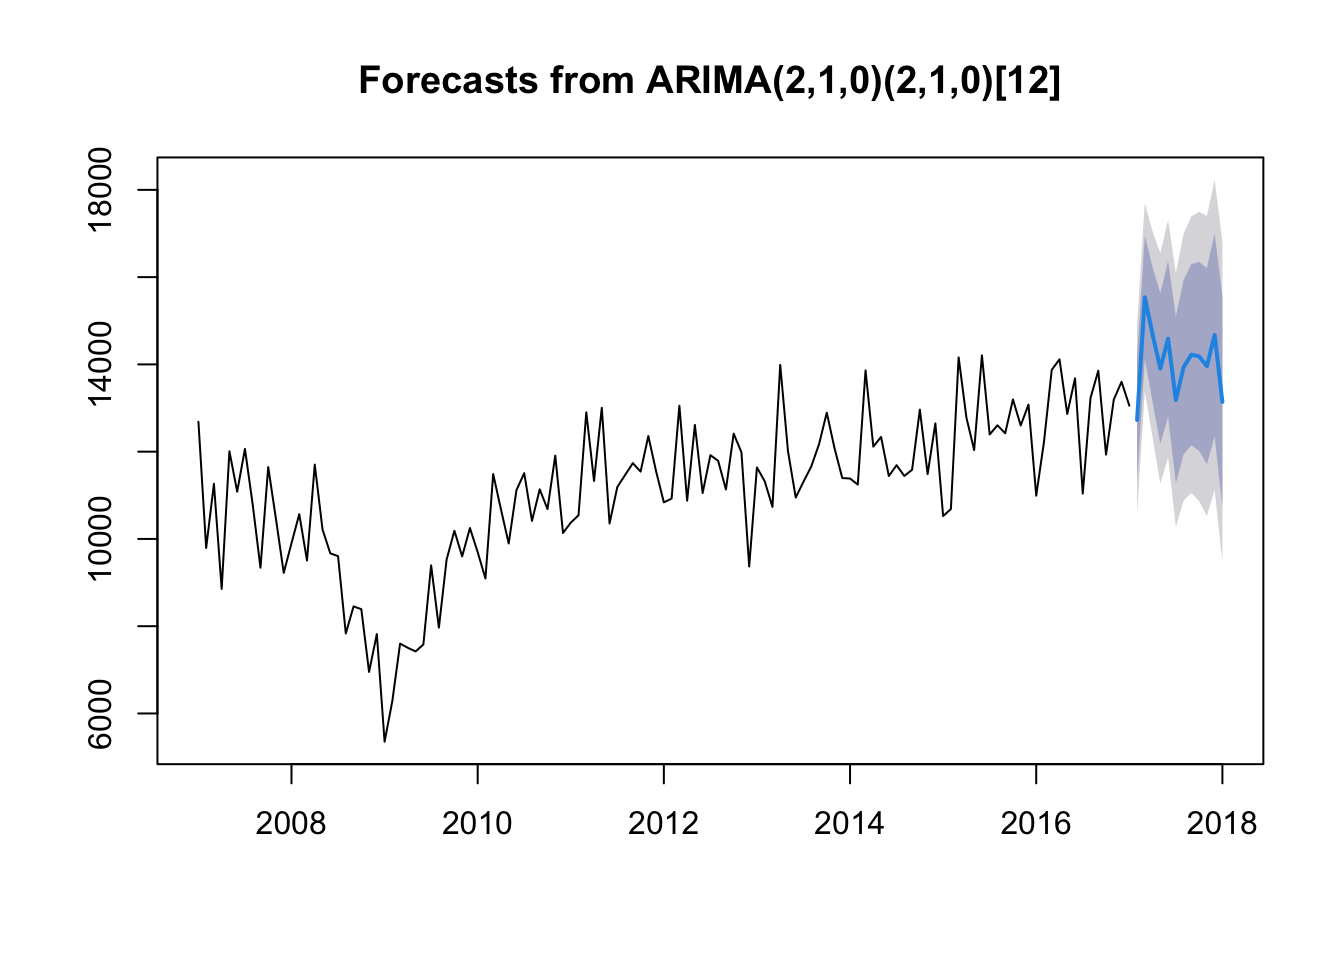{width="672"}

Tahminlerin güven aralığının dar olduğu gözükmektedir.HoltWinters'a
benzer bir grafik oluştuğu fark edilmiştir.

In [ ]:
%%R
finalforecast

In [ ]:
##          Point Forecast    Lo 80    Hi 80     Lo 95    Hi 95
## Feb 2017       12727.25 11323.87 14130.63 10580.961 14873.53
## Mar 2017       15536.78 14124.72 16948.84 13377.218 17696.34
## Apr 2017       14686.38 13142.60 16230.16 12325.376 17047.39
## May 2017       13905.22 12176.68 15633.77 11261.640 16548.80
## Jun 2017       14589.02 12808.36 16369.68 11865.729 17312.31
## Jul 2017       13184.53 11282.52 15086.54 10275.656 16093.40
## Aug 2017       13936.85 11938.14 15935.57 10880.086 16993.62
## Sep 2017       14223.23 12149.55 16296.91 11051.813 17394.65
## Oct 2017       14183.30 12015.43 16351.18 10867.822 17498.78
## Nov 2017       13960.07 11713.47 16206.68 10524.187 17395.96
## Dec 2017       14675.40 12352.35 16998.45 11122.604 18228.20
## Jan 2018       13140.21 10738.63 15541.79  9467.307 16813.11

Tahminlerin 13000-14000 bandında olduğu gözükmektedir.
:::
::::::::
:::::::::::::